<a href="https://colab.research.google.com/github/bejon23/Computational-Biology-and-BI-Eng/blob/main/GiG3_Project_6(f)_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 0

In [ ]:

# Cancer Genomics Evidence Lab
### Real tools. Real data. One reproducible workflow.

## The Problem
AI models often give biology answers that sound confident but use the wrong filter, the wrong tool, or claims that data cannot support. An expert reviewer cannot judge such answers by theory alone. The reviewer must run real tools on real data and show the evidence.

## What This Notebook Proves
1. **Variants and reads:** run samtools and bcftools, and show how filters change Ti/Tv, precision and recall.
2. **Workflow:** wrap the same steps in Snakemake and show the result is identical and reproducible.
3. **Single-cell:** analyse real PBMC data, check marker genes against known biology, and flag the pseudoreplication trap.
4. **Structure:** analyse the real p53-DNA structure (PDB 1TUP) to see which cancer hotspot residues touch DNA.
5. **Drug discovery:** score cancer drugs for drug-likeness with RDKit.
6. **Reproducibility:** save a run log with tool versions and file fingerprints.

## Data Honesty
| Part | Data | Tools |
|---|---|---|
| Reads and variants | Simulated (known truth) | Real samtools, bcftools |
| Single-cell | Real PBMC data (scanpy example) | Real scanpy |
| Structure | Real PDB entry 1TUP | Real Biopython |
| Drugs | Real drug structures | Real RDKit |

This lab is for method review and benchmarking. It makes no clinical claims.


## Cell 1: Setup
We install the tools, make a work folder, and record every version. A result without versions cannot be reproduced.

In [ ]:

# CELL 1: Setup, install tools, record versions
import subprocess, sys, os, platform, warnings
warnings.filterwarnings("ignore")

def sh(cmd, check=True):
    """Run a shell command and return its text output."""
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if check and r.returncode != 0:
        raise RuntimeError(f"Command failed: {cmd}\n{r.stderr[-800:]}")
    return r.stdout.strip()

print("Installing samtools and bcftools...")
sh("apt-get -qq update", check=False)
sh("apt-get -qq install -y samtools bcftools")
print("Installing Python packages (scanpy, biopython, rdkit)...")
sh(f"{sys.executable} -m pip -q install scanpy biopython rdkit")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scanpy as sc, Bio, rdkit

SEED = 42
WORK = os.path.abspath("lab")
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
summary = {}   # we fill this in every cell

versions = {
    "python": platform.python_version(),
    "numpy": np.__version__, "pandas": pd.__version__,
    "scanpy": sc.__version__, "biopython": Bio.__version__, "rdkit": rdkit.__version__,
    "samtools": sh("samtools --version | head -1"),
    "bcftools": sh("bcftools --version | head -1"),
    "seed": SEED,
}
for k, v in versions.items():
    print(f"  {k}: {v}")
print("\nWork folder:", WORK)

Installing samtools and bcftools...
Installing Python packages (scanpy, biopython, rdkit)...
  python: 3.13.16
  numpy: 2.1.3
  pandas: 3.1.0
  scanpy: 1.12.4
  biopython: 1.88
  rdkit: 2026.09.1
  samtools: samtools 1.19.2
  bcftools: bcftools 1.19
  seed: 42

Work folder: /content/lab


## Cell 2: Real samtools and bcftools
We simulate reads and variants with a known truth, then use the real command-line tools.
- **samtools** converts, sorts and counts reads (flagstat, MAPQ filter).
- **bcftools** filters variants and reports Ti/Tv.

Good variant sets have Ti/Tv near 2.0 to 2.1 for whole genome and near 3 for exome. A low Ti/Tv means many false calls.

[samtools flagstat]
440 + 0 in total (QC-passed reads + QC-failed reads)
440 + 0 primary
0 + 0 secondary
0 + 0 supplementary
0 + 0 duplicates
0 + 0 primary duplicates
400 + 0 mapped (90.91% : N/A)
400 + 0 primary mapped (90.91% : N/A)
0 + 0 paired in sequencing
0 + 0 read1
0 + 0 read2
0 + 0 properly paired (N/A : N/A)
0 + 0 with itself and mate mapped
0 + 0 singletons (N/A : N/A)
0 + 0 with mate mapped to a different chr
0 + 0 with mate mapped to a different chr (mapQ>=5)

Mapped reads with MAPQ >= 10: 380  (we built 380, so this should match)

[bcftools filtering vs known truth]
                           kept  precision  recall  Ti/Tv
filter                                                   
No filter                  3000      0.833   1.000   1.56
Weak (QUAL>=10)            2950      0.847   1.000   1.58
Strong (QUAL>=30, DP>=15)  2456      0.974   0.957   1.90


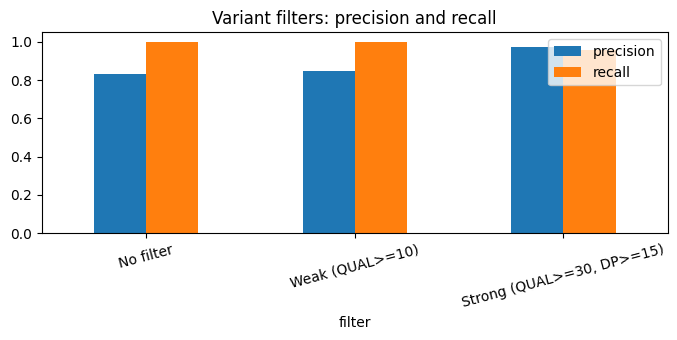


Lesson: the strong filter raises precision and moves Ti/Tv closer to 2.1.
Note: Ti/Tv near 2.1 is for whole genome. For exome, expect about 3.


In [ ]:

# CELL 2: samtools + bcftools on simulated reads and variants
rng = np.random.default_rng(SEED)

# ---------- A. Reads (SAM text file -> BAM with samtools) ----------
ref = "".join(rng.choice(list("ACGT"), 5000))
sam = ["@HD\tVN:1.6\tSO:unsorted", "@SQ\tSN:chr1\tLN:5000"]

def read_line(i, flag, pos, mapq, seq):
    return f"read{i}\t{flag}\tchr1\t{pos}\t{mapq}\t{len(seq)}M\t*\t0\t0\t{seq}\t{'I'*len(seq)}"

i = 0
for _ in range(380):                      # 380 good reads (MAPQ 60)
    pos = int(rng.integers(1, 4952))
    sam.append(read_line(i, int(rng.choice([0, 16])), pos, 60, ref[pos-1:pos+49])); i += 1
for _ in range(20):                       # 20 mapped reads with poor MAPQ (1)
    pos = int(rng.integers(1, 4952))
    sam.append(read_line(i, 0, pos, 1, ref[pos-1:pos+49])); i += 1
for _ in range(40):                       # 40 unmapped reads
    seq = "".join(rng.choice(list("ACGT"), 50))
    sam.append(f"read{i}\t4\t*\t0\t0\t*\t*\t0\t0\t{seq}\t{'I'*50}"); i += 1
open("reads.sam", "w").write("\n".join(sam) + "\n")

sh("samtools view -b -o reads.bam reads.sam")
sh("samtools sort -o sorted.bam reads.bam")
sh("samtools index sorted.bam")
print("[samtools flagstat]")
print(sh("samtools flagstat sorted.bam"))
good = int(sh("samtools view -c -F 4 -q 10 sorted.bam"))
print(f"\nMapped reads with MAPQ >= 10: {good}  (we built 380, so this should match)")
summary["reads_good_mapq"] = good

# ---------- B. Variants (VCF text file -> bcftools) ----------
TI = {"A": "G", "G": "A", "C": "T", "T": "C"}                 # transitions
TV = {"A": ["C", "T"], "G": ["C", "T"], "C": ["A", "G"], "T": ["A", "G"]}  # transversions
n_true, n_false = 2500, 500
positions = np.sort(rng.choice(np.arange(1000, 1_000_000), n_true + n_false, replace=False))
is_true = np.r_[np.ones(n_true, bool), np.zeros(n_false, bool)]
rng.shuffle(is_true)

rows = []
for pos, ok in zip(positions, is_true):
    r = str(rng.choice(list("ACGT")))
    if ok:   # real variants: Ti/Tv about 2.1, good quality and depth
        a = TI[r] if rng.random() < 2.1 / 3.1 else str(rng.choice(TV[r]))
        q = float(np.clip(rng.normal(60, 15), 1, 99)); dp = int(np.clip(rng.normal(35, 10), 1, 200))
    else:    # artifacts: random alleles, low quality and depth
        a = str(rng.choice([b for b in "ACGT" if b != r]))
        q = float(np.clip(rng.normal(25, 12), 1, 99)); dp = int(np.clip(rng.normal(12, 6), 1, 200))
    rows.append(f"chr1\t{int(pos)}\t.\t{r}\t{a}\t{q:.1f}\t.\tDP={dp}")

header = ["##fileformat=VCFv4.2", "##contig=<ID=chr1,length=1000000>",
          '##INFO=<ID=DP,Number=1,Type=Integer,Description="Read depth">',
          "#CHROM\tPOS\tID\tREF\tALT\tQUAL\tFILTER\tINFO"]
open("variants.vcf", "w").write("\n".join(header + rows) + "\n")
truth_pos = set(int(p) for p in positions[is_true])

def parse_titv(stats_text):
    for line in stats_text.splitlines():
        if line.startswith("TSTV"):
            return float(line.split("\t")[4])
    return None

def titv(vcf):
    return parse_titv(sh(f"bcftools stats {vcf}"))

sh("bcftools view -i 'QUAL>=10' variants.vcf -o weak.vcf")
sh("bcftools view -i 'QUAL>=30 && INFO/DP>=15' variants.vcf -o strong.vcf")

table = []
for label, f in [("No filter", "variants.vcf"), ("Weak (QUAL>=10)", "weak.vcf"),
                 ("Strong (QUAL>=30, DP>=15)", "strong.vcf")]:
    kept = set(pd.read_csv(f, sep="\t", comment="#", header=None, usecols=[1])[1])
    tp = len(kept & truth_pos)
    table.append({"filter": label, "kept": len(kept),
                  "precision": round(tp / len(kept), 3),
                  "recall": round(tp / len(truth_pos), 3),
                  "Ti/Tv": titv(f)})
variant_table = pd.DataFrame(table).set_index("filter")
print("\n[bcftools filtering vs known truth]")
print(variant_table)
summary["variant_table"] = variant_table.reset_index().to_dict("records")

variant_table[["precision", "recall"]].plot(kind="bar", ylim=(0, 1.05), rot=15, figsize=(7, 3.5))
plt.title("Variant filters: precision and recall"); plt.tight_layout(); plt.show()
print("\nLesson: the strong filter raises precision and moves Ti/Tv closer to 2.1.")
print("Note: Ti/Tv near 2.1 is for whole genome. For exome, expect about 3.")

## Cell 3: Reproducible workflow with Snakemake
Typing commands by hand is hard to repeat. A workflow tool records every step and its inputs and outputs.
We write a `Snakefile`, run a dry run first, then the real run, and check that the result matches Cell 2.

In [ ]:

# CELL 3: Snakemake workflow
import hashlib, shutil

snakefile = '''
rule all:
    input:
        "results/raw.stats.txt",
        "results/strong.stats.txt"

rule stats_raw:
    input: "variants.vcf"
    output: "results/raw.stats.txt"
    shell: "bcftools stats {input} > {output}"

rule filter_strong:
    input: "variants.vcf"
    output: "results/strong.vcf"
    shell: "bcftools view -i 'QUAL>=30 && INFO/DP>=15' {input} -o {output}"

rule stats_strong:
    input: "results/strong.vcf"
    output: "results/strong.stats.txt"
    shell: "bcftools stats {input} > {output}"
'''
open("Snakefile", "w").write(snakefile)

env_lines = ["name: cancer-genomics-lab", "dependencies:"] + \
            [f"  - {k}: {v}" for k, v in versions.items()]
open("environment_record.txt", "w").write("\n".join(env_lines) + "\n")

sh(f"{sys.executable} -m pip -q install snakemake", check=False)
shutil.rmtree("results", ignore_errors=True)

dry = subprocess.run(f"{sys.executable} -m snakemake --cores 1 -n",
                     shell=True, capture_output=True, text=True)
print("Dry run OK:", dry.returncode == 0)

run = subprocess.run(f"{sys.executable} -m snakemake --cores 1",
                     shell=True, capture_output=True, text=True)
print("Workflow run OK:", run.returncode == 0)

if run.returncode == 0:
    wf_titv = parse_titv(open("results/strong.stats.txt").read())
    manual_titv = titv("strong.vcf")
    same = (wf_titv == manual_titv)
    print(f"Workflow Ti/Tv: {wf_titv} | Manual Ti/Tv: {manual_titv} | Same result: {same}")
    summary["snakemake_same_result"] = bool(same)
else:
    print("Snakemake did not run. Last lines of its log:")
    print(run.stderr[-1500:])
    summary["snakemake_same_result"] = None

def md5(path):
    return hashlib.md5(open(path, "rb").read()).hexdigest()[:12]
summary["fingerprints"] = {"variants.vcf": md5("variants.vcf"), "strong.vcf": md5("strong.vcf"),
                           "Snakefile": md5("Snakefile")}
print("File fingerprints:", summary["fingerprints"])

Dry run OK: True
Workflow run OK: True
Workflow Ti/Tv: 1.9 | Manual Ti/Tv: 1.9 | Same result: True
File fingerprints: {'variants.vcf': '81d129b062f4', 'strong.vcf': 'ce2b55dc935e', 'Snakefile': '8d4ae9a79aeb'}


## Cell 4: Real single-cell data
We use a real PBMC (blood immune cells) dataset that comes inside scanpy. We check the data quality, find marker genes for each cell type, and compare them with known biology.
**Trap to remember:** cells from one donor are not independent replicates. Testing thousands of cells makes p-values look too strong (pseudoreplication). For case vs control, use pseudobulk per donor.

AnnData object with n_obs × n_vars = 700 × 765
    obs: 'bulk_labels', 'n_genes', 'percent_mito', 'n_counts', 'S_score', 'G2M_score', 'phase', 'louvain'
    var: 'n_counts', 'means', 'dispersions', 'dispersions_norm', 'highly_variable'
    uns: 'bulk_labels_colors', 'louvain', 'louvain_colors', 'neighbors', 'pca', 'rank_genes_groups'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: None (.X)

Cell types:
bulk_labels
Dendritic                       240
CD14+ Monocyte                  129
CD19+ B                          95
CD4+/CD25 T Reg                  68
CD8+ Cytotoxic T                 54
CD8+/CD45RA+ Naive Cytotoxic     43
CD56+ NK                         31
CD4+/CD45RO+ Memory              19
CD34+                            13
CD4+/CD45RA+/CD25- Naive T        8
Name: count, dtype: int64

[QC summary]
       n_counts  n_genes  percent_mito
count    700.00   700.00        700.00
mean    3506.44  1185.80          0.02
std      839.29 

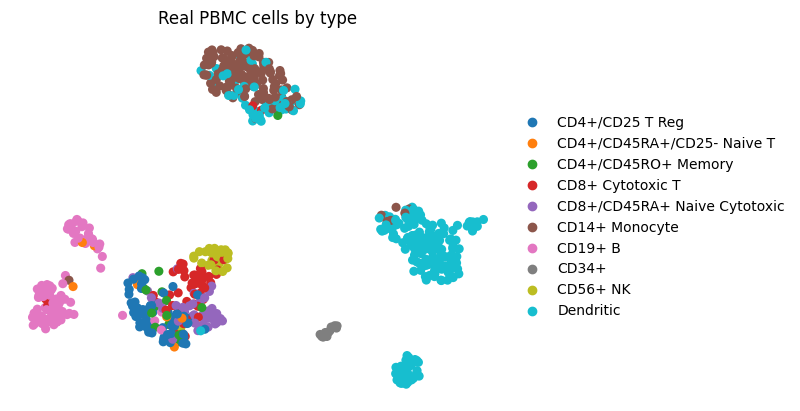


Expert warning: these p-values treat each cell as an independent replicate.
For disease vs control, make pseudobulk counts per donor, then use PyDESeq2 or edgeR.


In [ ]:

# CELL 4: Real single-cell data with scanpy
adata = sc.datasets.pbmc68k_reduced()
label = "bulk_labels" if "bulk_labels" in adata.obs else "louvain"
print(adata)
print("\nCell types:")
print(adata.obs[label].value_counts())

qc_cols = [c for c in ["n_counts", "n_genes", "percent_mito"] if c in adata.obs]
if qc_cols:
    print("\n[QC summary]")
    print(adata.obs[qc_cols].describe().round(2))

# Marker genes for each cell type (groups with at least 10 cells)
counts = adata.obs[label].value_counts()
groups = [g for g in counts.index if counts[g] >= 10]
sc.tl.rank_genes_groups(adata, label, groups=groups, reference="rest", method="wilcoxon")

known = {"CD14+ Monocyte": ["LYZ", "CST3", "S100A9", "S100A8"],
         "CD19+ B": ["CD79A", "CD79B", "MS4A1", "CD74"],
         "CD56+ NK": ["NKG7", "GNLY", "GZMB"],
         "CD8+ Cytotoxic T": ["CD8A", "CCL5", "GZMH", "NKG7"],
         "Dendritic": ["FCER1A", "HLA-DPB1", "CST3"]}

rows, hits = [], {}
for g in groups:
    top25 = sc.get.rank_genes_groups_df(adata, group=g).head(25)["names"].tolist()
    found = [m for m in known.get(g, []) if m in top25]
    hits[g] = found
    rows.append({"cell type": g, "top 5 genes": ", ".join(top25[:5]),
                 "known markers in top 25": ", ".join(found) if found else
                 ("none" if g in known else "(no reference list)")})
print("\n[Marker check against known biology]")
print(pd.DataFrame(rows).to_string(index=False))
summary["single_cell_marker_hits"] = hits

try:
    sc.pl.umap(adata, color=label, frameon=False, title="Real PBMC cells by type", show=True)
except Exception as e:
    print("UMAP plot skipped:", e)

print("\nExpert warning: these p-values treat each cell as an independent replicate.")
print("For disease vs control, make pseudobulk counts per donor, then use PyDESeq2 or edgeR.")

## Cell 5: Real protein structure (p53 bound to DNA)
We download PDB entry **1TUP** (p53 DNA-binding domain with DNA). Common p53 cancer hotspot residues are R175, G245, R248, R249, R273 and R282.
The literature says R248 and R273 touch DNA directly, while the others mostly change the protein shape. We measure the distance from each hotspot to the DNA and see what the data says.
We also use a BLOSUM62 substitution score. This is a simple conservation score and it is **not** a pathogenicity predictor.

In [ ]:

# CELL 5: Structure analysis with Biopython
import requests
from Bio.PDB import PDBParser
from Bio.SeqUtils import seq1
from Bio import Align
from Bio.Align import substitution_matrices
from scipy.spatial import cKDTree

pdb_id = "1TUP"
structure_ok = True
try:
    r = requests.get(f"https://files.rcsb.org/download/{pdb_id}.pdb", timeout=60)
    r.raise_for_status()
    open(f"{pdb_id}.pdb", "w").write(r.text)
except Exception as e:
    structure_ok = False
    print("Could not download the PDB file. Check internet and re-run this cell.\n", e)

if structure_ok:
    AA3 = set("ALA ARG ASN ASP CYS GLN GLU GLY HIS ILE LEU LYS MET PHE PRO SER THR TRP TYR VAL".split())
    DNA = {"DA", "DT", "DG", "DC"}
    model = PDBParser(QUIET=True).get_structure(pdb_id, f"{pdb_id}.pdb")[0]

    def is_prot(res): return res.id[0] == " " and res.get_resname().strip().upper() in AA3
    def is_dna(res):  return res.get_resname().strip().upper() in DNA

    print("[Chains in the structure]")
    for ch in model:
        n_prot = sum(1 for x in ch if is_prot(x)); n_dna = sum(1 for x in ch if is_dna(x))
        print(f"  Chain {ch.id}: {n_prot} protein residues, {n_dna} DNA nucleotides")

    dna_xyz = np.array([a.coord for x in model.get_residues() if is_dna(x) for a in x])
    tree = cKDTree(dna_xyz)

    hotspots = {175: "R", 245: "G", 248: "R", 249: "R", 273: "R", 282: "R"}
    prot_chains = [ch.id for ch in model if sum(1 for x in ch if is_prot(x)) > 100]

    dist_rows = []
    for ch in model:
        if ch.id not in prot_chains:
            continue
        for num, aa in hotspots.items():
            res = next((x for x in ch if is_prot(x) and x.id[1] == num), None)
            if res is None or seq1(res.get_resname()) != aa:
                continue
            d, _ = tree.query([a.coord for a in res])
            dist_rows.append({"residue": f"{aa}{num}", "chain": ch.id, "min_dist_to_DNA_A": round(float(d.min()), 1)})

    dist_df = pd.DataFrame(dist_rows)
    if len(dist_df):
        pivot = dist_df.pivot(index="residue", columns="chain", values="min_dist_to_DNA_A")
        pivot["closest"] = pivot.min(axis=1)
        pivot = pivot.sort_values("closest")
        print("\n[Closest distance from each hotspot residue to DNA, in Angstrom]")
        print(pivot)
        print("\nLiterature expects R248 and R273 (DNA-contact hotspots) to be the closest. Check the table.")
        print("Chains can differ: not every p53 monomer in the crystal touches the DNA.")
        summary["hotspot_closest_A"] = pivot["closest"].to_dict()

    # ---- Mutation scoring with a real alignment tool ----
    chain = next(ch for ch in model if ch.id in prot_chains)
    res_list = [x for x in chain if is_prot(x)]
    seq = "".join(seq1(x.get_resname()) for x in res_list)
    numbers = [x.id[1] for x in res_list]

    aligner = Align.PairwiseAligner()
    aligner.mode = "global"
    aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
    aligner.open_gap_score, aligner.extend_gap_score = -10, -0.5
    blosum = substitution_matrices.load("BLOSUM62")

    mutations = ["R175H", "G245S", "R248Q", "R249S", "R273H", "R282W"]
    mrows = []
    for m in mutations:
        wt, pos, mt = m[0], int(m[1:-1]), m[-1]
        if pos not in numbers:
            continue
        idx = numbers.index(pos)
        if seq[idx] != wt:
            continue
        mut_seq = seq[:idx] + mt + seq[idx + 1:]
        mismatches = sum(a != b for a, b in zip(seq, mut_seq))
        mrows.append({"mutation": m, "mismatches": mismatches,
                      "BLOSUM62": int(blosum[wt][mt]),
                      "alignment_score_drop": round(aligner.score(seq, seq) - aligner.score(seq, mut_seq), 1)})
    if mrows:
        print("\n[Hotspot mutations: substitution scores]")
        print(pd.DataFrame(mrows).to_string(index=False))
        print("\nCaution: a BLOSUM score tells how conservative a swap is. It does NOT tell if a variant")
        print("causes cancer. For that, use curated evidence (for example ClinVar) and functional data.")

[Chains in the structure]
  Chain E: 0 protein residues, 21 DNA nucleotides
  Chain F: 0 protein residues, 21 DNA nucleotides
  Chain A: 196 protein residues, 0 DNA nucleotides
  Chain B: 194 protein residues, 0 DNA nucleotides
  Chain C: 195 protein residues, 0 DNA nucleotides

[Closest distance from each hotspot residue to DNA, in Angstrom]
chain       A     B     C  closest
residue                           
R273     12.1   2.5   4.9      2.5
R248      5.3   3.4   3.2      3.2
R249      5.6   6.3   6.0      5.6
G245     10.3   9.7  10.5      9.7
R282     13.3   9.8  10.4      9.8
R175     17.3  13.2  14.3     13.2

Literature expects R248 and R273 (DNA-contact hotspots) to be the closest. Check the table.
Chains can differ: not every p53 monomer in the crystal touches the DNA.

[Hotspot mutations: substitution scores]
mutation  mismatches  BLOSUM62  alignment_score_drop
   R175H           1         0                   5.0
   G245S           1         0                   6.0
   R248Q

## Cell 6: Drug-likeness with RDKit, final scorecard and run log
We score five molecules with Lipinski's rule of five and QED. **Olaparib** is a PARP inhibitor used in BRCA-mutated cancers.
The rule of five is a guide for oral drugs, not a law. Many good drugs break it.
At the end we save a run log (versions, seed, fingerprints, key results) so another scientist can repeat the work.

[Drug-likeness]
                                MW  logP  HBD  HBA  TPSA  RotB   QED  \
drug                                                                   
Olaparib (PARP inhibitor)    434.5  2.35    1    4  86.4     4  0.68   
Imatinib (kinase inhibitor)  493.6  4.59    2    7  86.3     7  0.39   
Tamoxifen (ER modulator)     371.5  6.00    0    2  12.5     8  0.45   
Aspirin (reference)          180.2  1.31    1    3  63.6     2  0.55   
Caffeine (reference)         194.2 -1.03    0    3  61.8     0  0.54   

                             Ro5_violations  
drug                                         
Olaparib (PARP inhibitor)                 0  
Imatinib (kinase inhibitor)               0  
Tamoxifen (ER modulator)                  1  
Aspirin (reference)                       0  
Caffeine (reference)                      0  


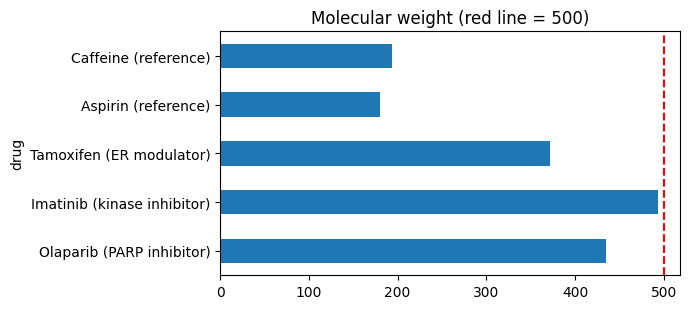


FINAL SCORECARD: claim -> proof from this lab
1. Variant filters  -> strong filter precision 0.974 (no filter: 0.833), Ti/Tv 1.56 -> 1.9
2. Workflow         -> Snakemake gives the same result as manual run: True
3. Single-cell      -> marker genes checked against known biology for 9 cell types
4. Structure        -> hotspot-to-DNA distances measured: {'R273': 2.5, 'R248': 3.2, 'R249': 5.6, 'G245': 9.7, 'R282': 9.8, 'R175': 13.2}
5. Drug-likeness    -> 5 molecules scored with RDKit
6. Reproducibility  -> run log saved below

Saved: run_log.json, Snakefile, environment_record.txt

LIMITS (say these honestly in an interview):
- Reads and variants are simulated. The tools are real, the data are not.
- The single-cell set is a small reduced PBMC dataset from one study.
- One structure (1TUP) cannot represent all p53 behaviour.
- Lipinski and BLOSUM scores are guides, not clinical evidence.


In [ ]:

# CELL 6: RDKit drug-likeness + scorecard + run log
import json
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, Lipinski, QED, rdMolDescriptors

drugs = {
    "Olaparib (PARP inhibitor)": "O=C(C1CC1)N1CCN(CC1)C(=O)c1cc(Cc2n[nH]c(=O)c3ccccc23)ccc1F",
    "Imatinib (kinase inhibitor)": "Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1",
    "Tamoxifen (ER modulator)": "CCC(=C(c1ccccc1)c1ccc(OCCN(C)C)cc1)c1ccccc1",
    "Aspirin (reference)": "CC(=O)Oc1ccccc1C(=O)O",
    "Caffeine (reference)": "CN1C=NC2=C1C(=O)N(C(=O)N2C)C",
}

drows = []
for name, smi in drugs.items():
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        print("Could not read SMILES for", name); continue
    mw, logp = Descriptors.MolWt(mol), Crippen.MolLogP(mol)
    hbd, hba = Lipinski.NumHDonors(mol), Lipinski.NumHAcceptors(mol)
    viol = int(mw > 500) + int(logp > 5) + int(hbd > 5) + int(hba > 10)
    drows.append({"drug": name, "MW": round(mw, 1), "logP": round(logp, 2), "HBD": hbd, "HBA": hba,
                  "TPSA": round(rdMolDescriptors.CalcTPSA(mol), 1),
                  "RotB": Lipinski.NumRotatableBonds(mol),
                  "QED": round(QED.qed(mol), 2), "Ro5_violations": viol})
drug_table = pd.DataFrame(drows).set_index("drug")
print("[Drug-likeness]")
print(drug_table)
summary["drug_table"] = drug_table.reset_index().to_dict("records")

ax = drug_table["MW"].plot(kind="barh", figsize=(7, 3.2))
ax.axvline(500, color="red", linestyle="--"); ax.set_title("Molecular weight (red line = 500)")
plt.tight_layout(); plt.show()

# ---------- Final scorecard ----------
print("\n" + "=" * 62)
print("FINAL SCORECARD: claim -> proof from this lab")
print("=" * 62)
vt = variant_table
print(f"1. Variant filters  -> strong filter precision {vt.iloc[2]['precision']} "
      f"(no filter: {vt.iloc[0]['precision']}), Ti/Tv {vt.iloc[0]['Ti/Tv']} -> {vt.iloc[2]['Ti/Tv']}")
print(f"2. Workflow         -> Snakemake gives the same result as manual run: {summary.get('snakemake_same_result')}")
print(f"3. Single-cell      -> marker genes checked against known biology for {len(summary.get('single_cell_marker_hits', {}))} cell types")
print(f"4. Structure        -> hotspot-to-DNA distances measured: {summary.get('hotspot_closest_A', 'not available')}")
print(f"5. Drug-likeness    -> {len(drug_table)} molecules scored with RDKit")
print("6. Reproducibility  -> run log saved below")

log = {"versions": versions, "seed": SEED, "summary": summary}
json.dump(log, open("run_log.json", "w"), indent=2, default=str)
print("\nSaved: run_log.json, Snakefile, environment_record.txt")

print("\nLIMITS (say these honestly in an interview):")
print("- Reads and variants are simulated. The tools are real, the data are not.")
print("- The single-cell set is a small reduced PBMC dataset from one study.")
print("- One structure (1TUP) cannot represent all p53 behaviour.")
print("- Lipinski and BLOSUM scores are guides, not clinical evidence.")